Saving dog-png-22650.png to dog-png-22650.png


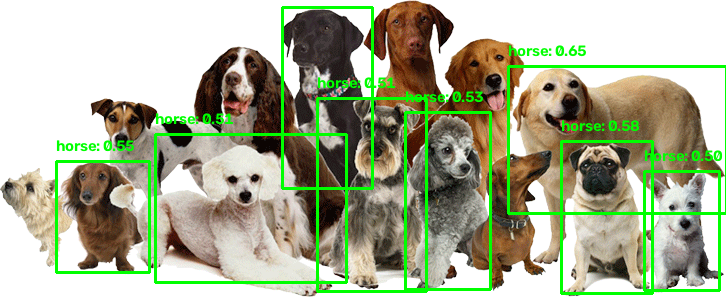

In [ ]:
import tensorflow_hub as hub # to download the ready-trained model
import tensorflow as tf # the deep-learning engine
import numpy as np # for working with number arrays
import cv2 # OpenCV: open images, draw boxes
from google.colab import files
from google.colab.patches import cv2_imshow # Colab’s replacement for cv2.imshow

# ---------------------------------------------------------------------------
# 2. LOAD THE PRE-TRAINED DETECTOR - "borrow the expert"
# ---------------------------------------------------------------------------
# EfficientDet-D0 is the smallest/fastest version (D0..D7 get bigger & sharper).
MODEL_URL = "https://tfhub.dev/tensorflow/efficientdet/d0/1"
detector = hub.load(MODEL_URL) # downloads once, then cached

# ---------------------------------------------------------------------------
# 3. CLASS NAMES - the 80 things the model can recognise (COCO dataset)
# ---------------------------------------------------------------------------
COCO_CLASSES = ["person", "bicycle", "car", "motorcycle", "airplane", "bus",
"train", "truck", "boat", "traffic light", "fire hydrant", "stop sign",
"parking meter", "bench", "bird", "cat", "dog", "horse", "sheep", "cow",
# ... (80 names in total) ...
"scissors", "teddy bear", "hair drier", "toothbrush"]
def detect_objects_with_boxes(image_path, detector):
  """Run the detector on one image and return the image with boxes drawn."""
  image = cv2.imread(image_path) # read image (BGR pixels)
  orig_image = image.copy() # clean copy to draw on
  input_tensor = tf.convert_to_tensor(image) # image → tensor
  input_tensor = input_tensor[tf.newaxis, ...] # add batch axis: "here is 1 photo"
  detections = detector(input_tensor) # one forward pass
  num_detections = int(detections["num_detections"])
  detection_boxes = detections["detection_boxes"].numpy()[0] # WHERE (fractions)
  detection_classes = detections["detection_classes"].numpy()[0].astype(np.int32) # WHAT
  detection_scores = detections["detection_scores"].numpy()[0] # HOW SURE
  confidence_threshold = 0.5 # ignore boxes below 50% sure
  for i in range(num_detections):
    score = detection_scores[i]
    if score > confidence_threshold:
      box = detection_boxes[i]
      h, w, _ = orig_image.shape
      y_min, x_min, y_max, x_max = box # note: y comes first
      x_min, x_max = int(x_min * w), int(x_max * w) # fractions → pixels
      y_min, y_max = int(y_min * h), int(y_max * h)
      class_id = detection_classes[i]
      class_name = COCO_CLASSES[class_id - 1] if 1 <= class_id <= 80 else "Unknown"
      label = f"{class_name}: {score:.2f}"
      cv2.rectangle(orig_image, (x_min, y_min), (x_max, y_max), (0, 255, 0), 2)
      cv2.putText(orig_image, label, (x_min, y_min - 10),
                cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)
  return orig_image

 # ---------------------------------------------------------------------------
 # 4. RUN IT - pick an image from the browser, detect, show
# --------------------------------------------------------------------------
uploaded = files.upload() # "Choose Files" button in the browser
image_path = next(iter(uploaded)) # the file the user picked
result_image = detect_objects_with_boxes(image_path, detector)
cv2_imshow(result_image) # show in Colab (NOT cv2.imshow)

In [ ]:
!pip install -q opencv-contrib-python

In [ ]:
import tensorflow as tf
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import (
    preprocess_input, decode_predictions
)
import numpy as np
import cv2
from google.colab import files
from google.colab.patches import cv2_imshow

# Load VGG16 pretrained on ImageNet
model = VGG16(weights="imagenet", include_top=True)

print("VGG16 model loaded successfully!")
print("Selective Search available:", hasattr(cv2, "ximgproc"))

553467096/553467096 ━━━━━━━━━━━━━━━━━━━━ 24s 0us/step
VGG16 model loaded successfully!
Selective Search available: True


In [ ]:
def get_region_proposals(img, max_regions=200):
    try:
        ss = cv2.ximgproc.segmentation.createSelectiveSearchSegmentation()
        ss.setBaseImage(img)
        ss.switchToSelectiveSearchFast()

        boxes = [
            (x, y, w, h)
            for x, y, w, h in ss.process()
            if w > 40 and h > 40
        ]

        if boxes:
            return boxes[:max_regions]

    except Exception as e:
        print("Selective Search unavailable; using sliding windows.")

    # Fallback: multi-scale sliding windows
    H, W = img.shape[:2]
    boxes = []

    for s in (0.6, 0.4, 0.25):
        bw, bh = int(W * s), int(H * s)

        if bw == 0 or bh == 0:
            continue

        for y in range(0, H - bh + 1, max(1, bh // 2)):
            for x in range(0, W - bw + 1, max(1, bw // 2)):
                boxes.append((x, y, bw, bh))

                if len(boxes) >= max_regions:
                    return boxes

    return boxes

In [ ]:
def non_max_suppression(dets, iou_thr=0.3):
    if not dets:
        return []

    boxes = np.array([
        [x, y, x + w, y + h]
        for (x, y, w, h), _, _ in dets
    ], dtype=float)

    scores = np.array([score for _, _, score in dets])
    order = scores.argsort()[::-1]
    keep = []

    while len(order) > 0:
        i = order[0]
        keep.append(i)
        rest = order[1:]

        if len(rest) == 0:
            break

        xx1 = np.maximum(boxes[i, 0], boxes[rest, 0])
        yy1 = np.maximum(boxes[i, 1], boxes[rest, 1])
        xx2 = np.minimum(boxes[i, 2], boxes[rest, 2])
        yy2 = np.minimum(boxes[i, 3], boxes[rest, 3])

        w = np.clip(xx2 - xx1, 0, None)
        h = np.clip(yy2 - yy1, 0, None)
        inter = w * h

        area_i = (
            (boxes[i, 2] - boxes[i, 0]) *
            (boxes[i, 3] - boxes[i, 1])
        )
        area_r = (
            (boxes[rest, 2] - boxes[rest, 0]) *
            (boxes[rest, 3] - boxes[rest, 1])
        )

        iou = inter / (area_i + area_r - inter + 1e-9)
        order = rest[iou < iou_thr]

    return [dets[i] for i in keep]

Saving [CITYPNG.COM]Cute Cats and Dogs Sitting Together HD Transparent PNG - 1000x1000.png to [CITYPNG.COM]Cute Cats and Dogs Sitting Together HD Transparent PNG - 1000x1000 (1).png
Selective Search unavailable; using sliding windows.
Regions generated: 69
basset: 0.97
French_bulldog: 0.90
Final detections: 2


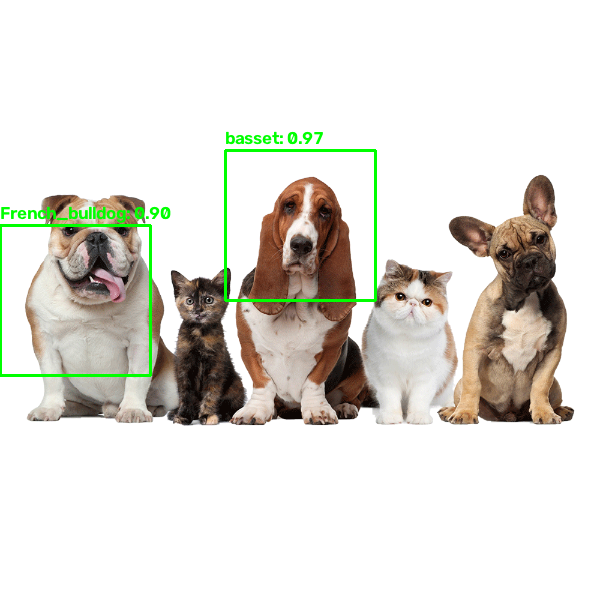

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Upload an image
uploaded = files.upload()

if uploaded:
    image_path = next(iter(uploaded))
    img = cv2.imread(image_path)

    if img is None:
        raise ValueError("Could not read the uploaded image.")

    # Resize to width 600 for faster processing
    H0, W0 = img.shape[:2]
    img = cv2.resize(img, (600, int(H0 * 600.0 / W0)))

    # Generate region proposals
    boxes = get_region_proposals(img, max_regions=200)
    print("Regions generated:", len(boxes))

    if not boxes:
        print("No regions were generated.")
    else:
        # Crop each region, resize to 224 x 224,
        # and convert BGR to RGB for VGG16 preprocessing
        crops = np.array([
            cv2.cvtColor(
                cv2.resize(img[y:y+h, x:x+w], (224, 224)),
                cv2.COLOR_BGR2RGB
            )
            for x, y, w, h in boxes
        ], dtype=np.float32)

        # Classify regions in batches
        preds = model.predict(
            preprocess_input(crops),
            batch_size=32,
            verbose=0
        )

        detections = []

        for box, prediction in zip(boxes, preds):
            _, label, prob = decode_predictions(
                prediction[None, :], top=1
            )[0][0]

            if prob > 0.90:
                detections.append((box, label, float(prob)))

        # Remove duplicate overlapping detections
        detections = non_max_suppression(
            detections, iou_thr=0.3
        )

        # Draw final boxes
        for (x, y, w, h), label, score in detections:
            cv2.rectangle(
                img, (x, y), (x+w, y+h), (0, 255, 0), 2
            )
            cv2.putText(
                img, f"{label}: {score:.2f}",
                (x, max(18, y-6)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.6, (0, 255, 0), 2
            )
            print(f"{label}: {score:.2f}")

        print("Final detections:", len(detections))
        cv2_imshow(img)

        cv2.imwrite("region_detection_output.jpg", img)
        files.download("region_detection_output.jpg")